# Retail Transaction Clustering Case Study

## Problem and objectives
An online retailer has basket-level transaction records but needs a systematic view of basket characteristics and groups of similar purchases. This notebook cleans the data, summarizes products and basket sizes, creates binary basket vectors, visualizes them with PCA, compares K-means, hierarchical clustering, DBSCAN, and spectral clustering, and closes with evidence-based conclusions and limitations.

**Dataset expectation:** one transaction per row, product names in columns, no header row, and blank cells where the basket has fewer products. The supplied file contains 7,501 rows and 20 item slots. The analysis is deterministic (`RANDOM_STATE = 42`).

## 1. Setup and data loading
In Colab, upload `Online retail_new.csv` when prompted. In a local notebook, place the CSV beside this notebook or set `RETAIL_CSV_PATH` to its location.

In [3]:
from pathlib import Path
import os, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
MAX_CLUSTER_SAMPLE = 800       # controls pairwise-distance and spectral-clustering cost
SILHOUETTE_SAMPLE = 500         # common evaluation subset for comparable scores
np.random.seed(RANDOM_STATE)

# Find the supplied CSV, or ask for it in Colab.
candidates = [Path(os.environ["RETAIL_CSV_PATH"])] if os.environ.get("RETAIL_CSV_PATH") else []
candidates += [Path("Online retail_new.csv"), Path("/mnt/data/Online retail_new.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError("CSV not found. Put 'Online retail_new.csv' beside this notebook or set RETAIL_CSV_PATH.") from exc

raw = pd.read_csv(DATA_PATH, header=None, dtype="string", encoding="unicode_escape")
print(f"Loaded: {DATA_PATH.name} | rows: {raw.shape[0]:,} | item slots: {raw.shape[1]}")
display(raw.head())

Loaded: Online retail_new.csv | rows: 7,501 | item slots: 20


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,chutney,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,turkey,avocado,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,mineral water,milk,energy bar,whole wheat rice,green tea,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


## 2. Inspect, clean, and describe the baskets
Blank cells are treated as missing item slots. Product text is normalized to lowercase and whitespace is trimmed. Two apparent spelling variants in this dataset are standardized. Repeated products within one row count once, because features represent product presence per basket.

In [5]:
print("Raw shape:", raw.shape)
print("Missing item slots:", int(raw.isna().sum().sum()))
print("Non-empty values:", int(raw.notna().sum().sum()))
print("\nNon-empty slots per basket (raw):")
display(raw.notna().sum(axis=1).describe().to_frame("items"))

FIX = {"whole weat flour": "whole wheat flour", "antioxydant juice": "antioxidant juice"}
def clean_basket(row):
    items = {str(x).strip().lower() for x in row if pd.notna(x) and str(x).strip()}
    return sorted({FIX.get(item, item) for item in items})

baskets = raw.apply(clean_basket, axis=1)
empty_count = int((baskets.str.len() == 0).sum())
baskets = baskets[baskets.str.len() > 0].reset_index(drop=True)
sizes = baskets.str.len()
product_counts = Counter(item for basket in baskets for item in basket)
top_products = pd.Series(product_counts, dtype="int64").sort_values(ascending=False)
print(f"\nEmpty baskets removed: {empty_count}")
print(f"Clean transactions: {len(baskets):,} | unique products: {len(product_counts)}")
print("\nBasket size statistics:")
display(sizes.describe().round(2).to_frame("items_per_basket"))
print(f"Single-item baskets: {(sizes == 1).mean():.1%}")
print("Top 15 products by number of baskets:")
display(top_products.head(15).rename("basket_count").to_frame())

Raw shape: (7501, 20)
Missing item slots: 120657
Non-empty values: 29363

Non-empty slots per basket (raw):

Empty baskets removed: 0
Clean transactions: 7,501 | unique products: 119

Basket size statistics:
Single-item baskets: 23.4%
Top 15 products by number of baskets:


,items
count,7501.000000
mean,3.914545
std,2.905540
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,20.000000


,items_per_basket
count,7501.00
mean,3.91
std,2.90
min,1.00
25%,2.00
50%,3.00
75%,5.00
max,20.00


,basket_count
mineral water,1788
eggs,1348
spaghetti,1306
french fries,1282
chocolate,1229
green tea,991
milk,972
ground beef,737
frozen vegetables,715
pancakes,713


## 3. Visualize product frequencies and basket sizes
Product frequency is the number of baskets containing a product, not the number of repeated units purchased.

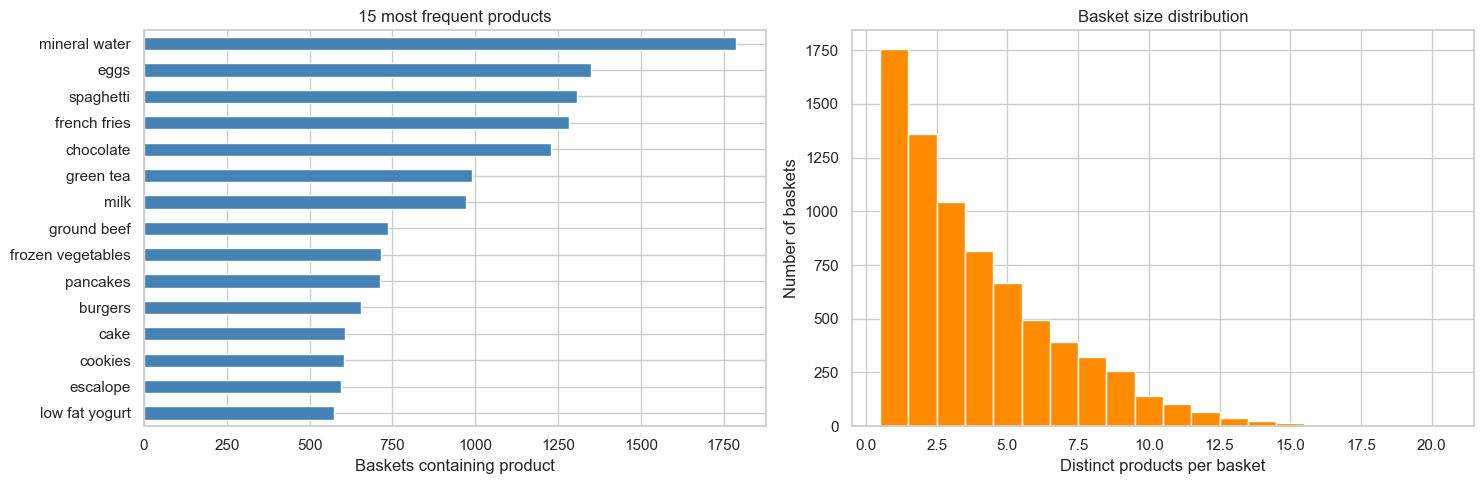

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_products.head(15).sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="15 most frequent products", xlabel="Baskets containing product", ylabel="")
axes[1].hist(sizes, bins=np.arange(0.5, sizes.max() + 1.5), color="darkorange", edgecolor="white")
axes[1].set(title="Basket size distribution", xlabel="Distinct products per basket", ylabel="Number of baskets")
plt.tight_layout(); plt.show()

## 4. Convert baskets to binary feature vectors
Each row is a basket; each column is a distinct product. A value of 1 means the product occurs in that basket.

In [9]:
mlb = MultiLabelBinarizer()
X = mlb.fit_transform(baskets).astype(np.uint8)
products = mlb.classes_
print("Feature matrix:", X.shape)
print(f"Density (fraction of basket-product pairs present): {X.mean():.3%}")
display(pd.DataFrame(X[:5], columns=products).iloc[:, :min(12, len(products))])

Feature matrix: (7501, 119)
Density (fraction of basket-product pairs present): 3.289%


,almonds,antioxidant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,bramble,brownies
0,1,1,0,1,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


## 5. PCA: dimensionality reduction and visualization
PCA is fitted on the full binary feature matrix for a global two-dimensional view. Binary transaction features are sparse in meaning; the plot is exploratory, and nearby points in this Euclidean PCA projection do not establish meaningful customer segments.

Variance explained by PC1 and PC2: [0.0672 0.0447]
Combined variance explained: 11.18%


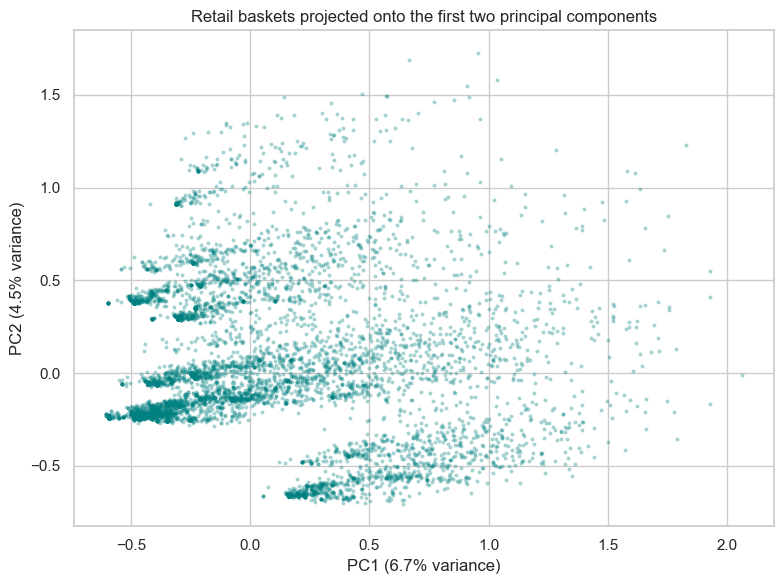

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X.astype(float))
print("Variance explained by PC1 and PC2:", np.round(pca.explained_variance_ratio_, 4))
print(f"Combined variance explained: {pca.explained_variance_ratio_.sum():.2%}")
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.35, color="teal", linewidths=0)
plt.title("Retail baskets projected onto the first two principal components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout(); plt.show()

## 6. Practical clustering sample and K-means selection
Distance-based silhouette scores scale quadratically with the number of rows. To keep execution practical, every clustering algorithm is fit to the same reproducible random sample (up to 800 baskets). K-means uses Euclidean distance and is evaluated with the same metric. The silhouette sample is selected once and reused for a fair, lower-cost comparison.

Clustering sample: 800 of 7,501 baskets
Common metric evaluation subset: 500 baskets
Selected k by sampled silhouette: 2


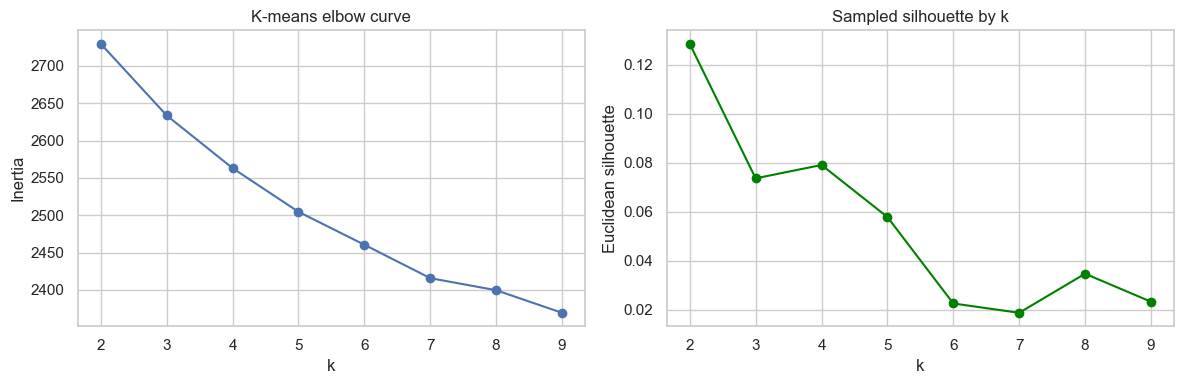

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
n_cluster = min(MAX_CLUSTER_SAMPLE, len(X))
cluster_idx = np.sort(rng.choice(len(X), size=n_cluster, replace=False))
X_cluster = X[cluster_idx].astype(float)
n_eval = min(SILHOUETTE_SAMPLE, n_cluster)
eval_idx = np.sort(rng.choice(n_cluster, size=n_eval, replace=False))
print(f"Clustering sample: {n_cluster:,} of {len(X):,} baskets")
print(f"Common metric evaluation subset: {n_eval:,} baskets")

# Select k by mean Euclidean silhouette on the same evaluation rows for each candidate.
k_values = list(range(2, min(9, n_cluster - 1) + 1))
k_inertia, k_silhouette = [], []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    lab = model.fit_predict(X_cluster)
    k_inertia.append(model.inertia_)
    k_silhouette.append(silhouette_score(X_cluster[eval_idx], lab[eval_idx], metric="euclidean"))
best_k = k_values[int(np.argmax(k_silhouette))]
print(f"Selected k by sampled silhouette: {best_k}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, k_inertia, "o-"); axes[0].set(title="K-means elbow curve", xlabel="k", ylabel="Inertia")
axes[1].plot(k_values, k_silhouette, "o-", color="green"); axes[1].set(title="Sampled silhouette by k", xlabel="k", ylabel="Euclidean silhouette")
plt.tight_layout(); plt.show()

## 7. Fit and compare four clustering algorithms
For comparability, all four algorithms are fitted on the same sampled baskets and scored on the same held-out subset of those sampled rows. Silhouette uses Jaccard distance for the binary basket algorithms; K-means uses Euclidean distance. Davies–Bouldin is defined with Euclidean cluster geometry, so it is reported for every algorithm but should be interpreted alongside the silhouette score. DBSCAN noise points (`-1`) are excluded from both scores; the noise percentage is reported. A score is omitted if a result has fewer than two non-noise clusters or one cluster per point.

In [15]:
# Hierarchical clustering uses average linkage with Jaccard distance.
hier_model = AgglomerativeClustering(n_clusters=best_k, metric="jaccard", linkage="average")
hier_labels = hier_model.fit_predict(X_cluster)

# DBSCAN eps heuristic: 90th percentile of each point's 5th-neighbor Jaccard distance.
min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples, metric="jaccard", n_jobs=-1).fit(X_cluster)
neighbor_dist, _ = nn.kneighbors(X_cluster)
eps = float(np.percentile(neighbor_dist[:, -1], 90))
if eps <= 0:
    eps = float(np.nextafter(0.0, 1.0))
dbscan_model = DBSCAN(eps=eps, min_samples=min_samples, metric="jaccard", n_jobs=-1)
dbscan_labels = dbscan_model.fit_predict(X_cluster)

# Spectral clustering uses a sparse nearest-neighbor graph to limit memory use.
spectral_neighbors = min(10, n_cluster - 1)
spectral_labels = SpectralClustering(
    n_clusters=best_k, affinity="nearest_neighbors", n_neighbors=spectral_neighbors,
    assign_labels="kmeans", n_init=10, random_state=RANDOM_STATE
).fit_predict(X_cluster)

cluster_labels = {
    "K-means": (KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_cluster), "euclidean"),
    "Hierarchical (Jaccard)": (hier_labels, "jaccard"),
    "DBSCAN (Jaccard)": (dbscan_labels, "jaccard"),
    "Spectral (kNN graph)": (spectral_labels, "jaccard"),
}
print(f"DBSCAN eps heuristic: {eps:.4f} | min_samples: {min_samples}")
for name, (lab, _) in cluster_labels.items():
    unique, counts = np.unique(lab, return_counts=True)
    print(f"{name}: {len(unique) - (1 if -1 in unique else 0)} clusters; sizes {dict(zip(unique.tolist(), counts.tolist()))}")

DBSCAN eps heuristic: 0.7500 | min_samples: 5
K-means: 2 clusters; sizes {0: 196, 1: 604}
Hierarchical (Jaccard): 2 clusters; sizes {0: 799, 1: 1}
DBSCAN (Jaccard): 1 clusters; sizes {-1: 5, 0: 795}
Spectral (kNN graph): 2 clusters; sizes {0: 744, 1: 56}


,Algorithm,Clusters (evaluation subset),Noise share,Silhouette,Davies–Bouldin,Silhouette metric
0,K-means,2,0.0%,0.1285,3.5789,euclidean
1,Hierarchical (Jaccard),1,0.0%,N/A,N/A,jaccard
2,DBSCAN (Jaccard),1,0.2%,N/A,N/A,jaccard
3,Spectral (kNN graph),2,0.0%,0.0582,2.4913,jaccard


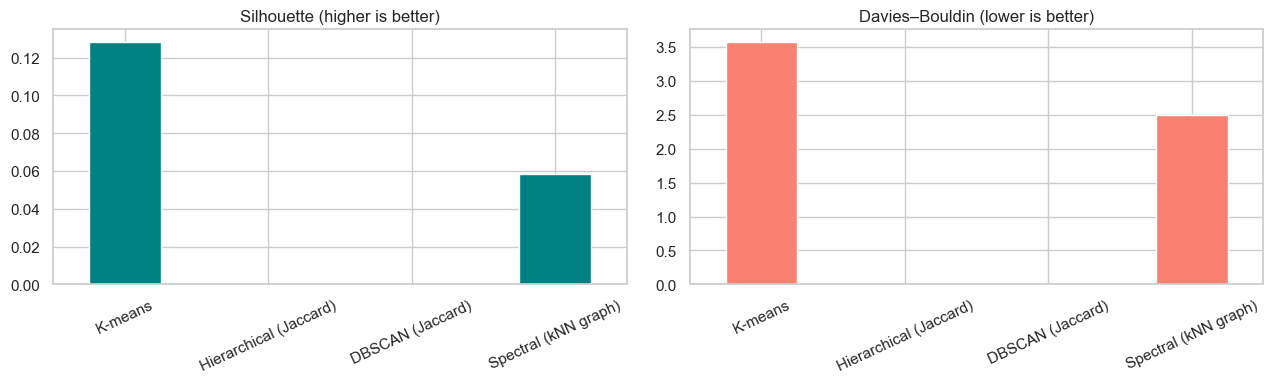

In [16]:
def safe_dbi(X_eval, labels_eval):
    unique = np.unique(labels_eval)
    if len(unique) < 2 or len(unique) >= len(labels_eval):
        return np.nan
    return davies_bouldin_score(X_eval, labels_eval)

rows = []
for name, (all_labels, metric) in cluster_labels.items():
    eval_labels = all_labels[eval_idx]
    noise = eval_labels == -1
    keep = ~noise
    n_clusters = len(set(eval_labels[keep]))
    if keep.sum() > 2 and 2 <= n_clusters < keep.sum():
        sil = silhouette_score(X_cluster[eval_idx][keep], eval_labels[keep], metric=metric)
        dbi = safe_dbi(X_cluster[eval_idx][keep], eval_labels[keep])
    else:
        sil, dbi = np.nan, np.nan
    rows.append({"Algorithm": name, "Clusters (evaluation subset)": n_clusters,
                 "Noise share": noise.mean(), "Silhouette": sil, "Davies–Bouldin": dbi,
                 "Silhouette metric": metric})
results = pd.DataFrame(rows)
display(results.style.format({"Noise share": "{:.1%}", "Silhouette": "{:.4f}", "Davies–Bouldin": "{:.4f}"}, na_rep="N/A"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title, color in [(axes[0], "Silhouette", "Silhouette (higher is better)", "teal"),
                              (axes[1], "Davies–Bouldin", "Davies–Bouldin (lower is better)", "salmon")]:
    vals = results.set_index("Algorithm")[col]
    vals.plot.bar(ax=ax, color=color, legend=False)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 8. Visualize sampled cluster assignments in PCA space
PCA coordinates are computed on the full dataset above; here we color sampled baskets by their algorithm labels. These plots show how assignments overlap with a linear 2D projection and cannot replace the quantitative metrics.

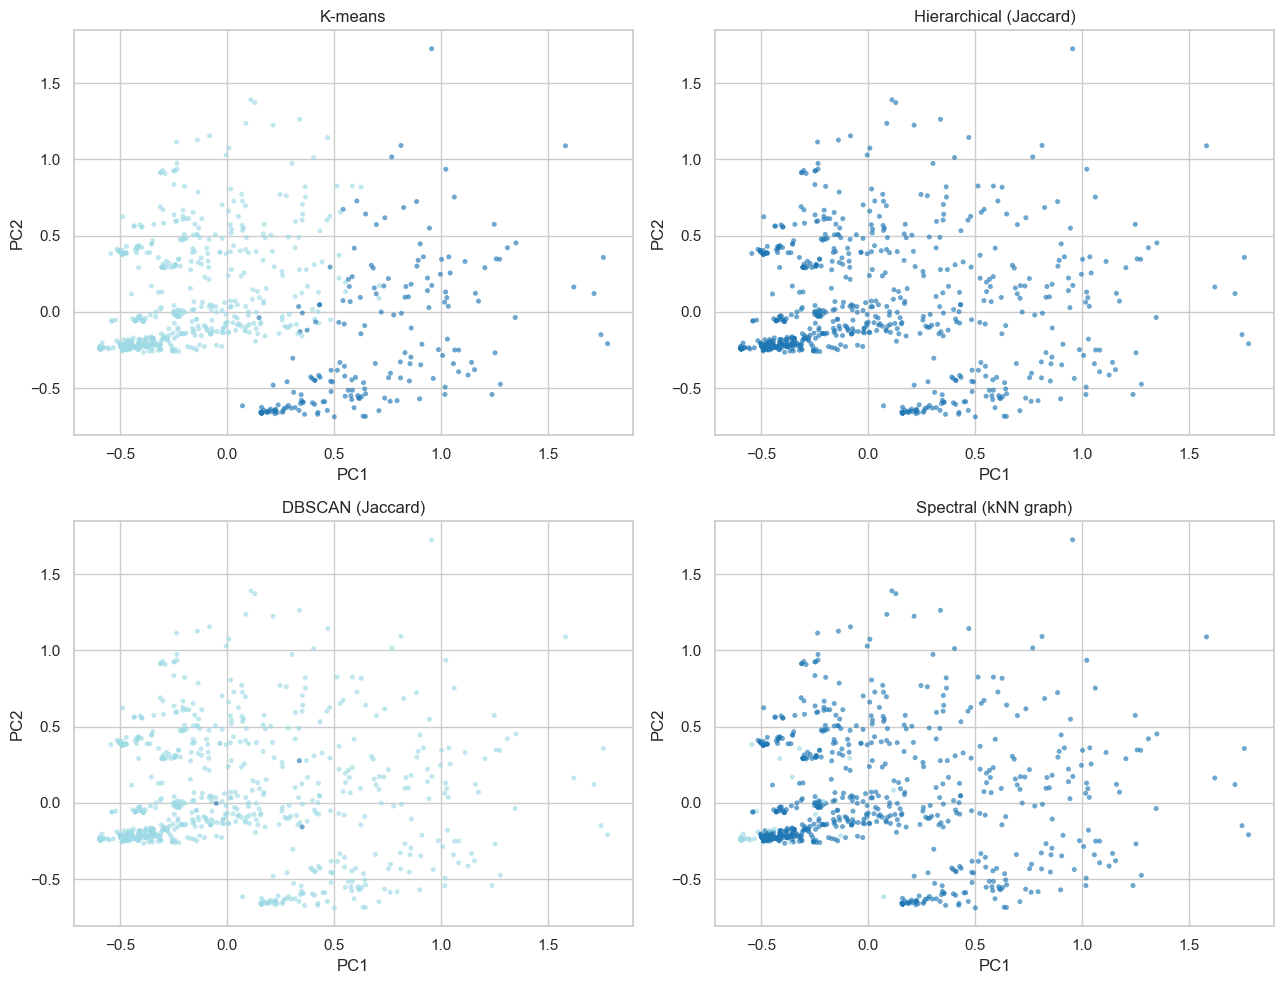

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, (lab, _)) in zip(axes.flat, cluster_labels.items()):
    scatter = ax.scatter(X_pca[cluster_idx, 0], X_pca[cluster_idx, 1], c=lab, s=13, alpha=0.65, cmap="tab20", linewidths=0)
    ax.set(title=name, xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

## 9. Interpret cluster profiles
Cluster descriptions use the most common products among sampled baskets assigned to each cluster. For DBSCAN, noise is summarized separately rather than described as a coherent segment.

In [20]:
def describe_clusters(basket_indices, labels, top_n=6):
    rows = []
    for label in sorted(np.unique(labels)):
        members = np.where(labels == label)[0]
        if label == -1:
            name = "Noise"
        else:
            name = f"Cluster {label}"
        counts = Counter(item for pos in members for item in baskets.iloc[basket_indices[pos]])
        rows.append({"Group": name, "Baskets": len(members), "Share": len(members) / len(labels),
                     "Most common products": ", ".join([p for p, _ in counts.most_common(top_n)])})
    return pd.DataFrame(rows)
for name, (lab, _) in cluster_labels.items():
    print("\n" + name)
    display(describe_clusters(cluster_idx, lab).style.format({"Share": "{:.1%}"}))


K-means

Hierarchical (Jaccard)

DBSCAN (Jaccard)

Spectral (kNN graph)


,Group,Baskets,Share,Most common products
0,Cluster 0,196,24.5%,"mineral water, spaghetti, chocolate, milk, frozen vegetables, eggs"
1,Cluster 1,604,75.5%,"french fries, eggs, green tea, chocolate, spaghetti, cookies"


,Group,Baskets,Share,Most common products
0,Cluster 0,799,99.9%,"mineral water, chocolate, french fries, spaghetti, eggs, green tea"
1,Cluster 1,1,0.1%,yams


,Group,Baskets,Share,Most common products
0,Noise,5,0.6%,"honey, eggplant, oil, chicken, herb & pepper, yams"
1,Cluster 0,795,99.4%,"mineral water, french fries, chocolate, spaghetti, eggs, green tea"


,Group,Baskets,Share,Most common products
0,Cluster 0,744,93.0%,"mineral water, chocolate, french fries, spaghetti, eggs, green tea"
1,Cluster 1,56,7.0%,"cookies, hot dogs, mushroom cream sauce, shrimp, cake, eggs"


## 10. Findings, business implications, and limitations
The following summary is generated from the executed results. Treat it as exploratory evidence for this dataset, rather than a validated segmentation of customers.

In [22]:
valid = results.dropna(subset=["Silhouette"])
if len(valid):
    best_row = valid.loc[valid["Silhouette"].idxmax()]
    print(f"Highest sampled silhouette: {best_row['Algorithm']} ({best_row['Silhouette']:.3f}; {best_row['Silhouette metric']} distance).")
else:
    print("No method produced enough distinct non-noise groups on the evaluation subset for a silhouette score.")
print(f"The two PCA components explain {pca.explained_variance_ratio_.sum():.1%} of the variance.")
print(f"The most frequent product is {top_products.index[0]!r}, appearing in {top_products.iloc[0]:,} baskets ({top_products.iloc[0]/len(baskets):.1%}).")
print(f"Median basket size is {sizes.median():.0f} distinct products; {sizes.mean():.2f} on average.")

Highest sampled silhouette: K-means (0.128; euclidean distance).
The two PCA components explain 11.2% of the variance.
The most frequent product is 'mineral water', appearing in 1,788 baskets (23.8%).
Median basket size is 3 distinct products; 3.91 on average.


### Practical conclusions
- Frequent products and basket-size statistics help prioritize assortment visibility, replenishment, and cross-sell experiments.
- Cluster profiles can suggest basket themes for follow-up analysis, but should not be treated as customer segments: each row is a transaction, and the file contains no customer identity, timestamp, price, quantity, or order context.
- Compare cluster profiles and sizes with business stakeholders before turning them into merchandising actions. Validate any proposed action with an experiment or a later time period.

### Limitations
- Clustering was performed on a reproducible sample for runtime. Sample results can vary and need not match a full-data fit.
- One-hot baskets are high-dimensional and sparse. Jaccard and Euclidean distances encode different notions of similarity; K-means optimizes Euclidean within-cluster sum of squares and is not naturally suited to binary sparse baskets.
- PCA preserves linear variance, not necessarily basket similarity. Two components may explain little variance and can hide structure.
- Silhouette and Davies–Bouldin favor compact, separated clusters and can underrate density-based or irregular shapes. DBSCAN is sensitive to `eps` and can label many rows as noise; its heuristic is not a business optimum.
- Hierarchical clustering and spectral clustering were run on the sample due to computational cost. Results depend on preprocessing, sample choice, distance/graph settings, and hyperparameters.
- A high internal metric does not prove that clusters are actionable, stable, profitable, or representative of customers. Validate stability and business value before deployment.

## Reproducibility and rerunning in Colab
The notebook fixes the random seed and records the sampling limits near the top. In Colab, run all cells from the beginning and upload the CSV when prompted. To reduce runtime further, lower `MAX_CLUSTER_SAMPLE` and `SILHOUETTE_SAMPLE`; for a more thorough analysis, increase them gradually.